In [1]:
import sys
import os

sys.path.append(os.path.abspath(".."))

In [2]:
import os
import numpy as np
from core.deeplearning.neural_network import NeuralNetwork
from utils import training, loss
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import kagglehub

np.random.seed(42)

#### Dataset ophalen en inladen

In [3]:
path = kagglehub.dataset_download("hojjatk/mnist-dataset")

path_train = os.path.join(path, "train-images-idx3-ubyte/train-images-idx3-ubyte")
path_train_label = os.path.join(path, "train-labels-idx1-ubyte/train-labels-idx1-ubyte")

path_test = os.path.join(path, "t10k-images-idx3-ubyte/t10k-images-idx3-ubyte")
path_test_label = os.path.join(path, "t10k-labels-idx1-ubyte/t10k-labels-idx1-ubyte")

In [4]:
with open(path_train, "rb") as f:
    magic_number = int.from_bytes(f.read(4), 'big')
    num_images = int.from_bytes(f.read(4), 'big')
    num_rows = int.from_bytes(f.read(4), 'big')
    num_cols = int.from_bytes(f.read(4), 'big')

    images_train = np.frombuffer(f.read(), dtype=np.uint8)

with open(path_train_label, "rb") as f:
    magic_number = int.from_bytes(f.read(4), 'big')
    num_labels = int.from_bytes(f.read(4), 'big')

    labels_train = np.frombuffer(f.read(), dtype=np.uint8)

with open(path_test, "rb") as f:
    magic_number = int.from_bytes(f.read(4), 'big')
    num_images_test = int.from_bytes(f.read(4), 'big')
    num_rows_test = int.from_bytes(f.read(4), 'big')
    num_cols_test = int.from_bytes(f.read(4), 'big')

    images_test = np.frombuffer(f.read(), dtype=np.uint8)

with open(path_test_label, "rb") as f:
    magic_number = int.from_bytes(f.read(4), 'big')
    num_labels = int.from_bytes(f.read(4), 'big')

    labels_test = np.frombuffer(f.read(), dtype=np.uint8)

print(images_train.shape, labels_train.shape, images_test.shape, labels_test.shape)


(47040000,) (60000,) (7840000,) (10000,)


#### Dataset

De input data wordt hervormd tot arrays van 784 pixels (afbeeldingen zijn 28 x 28 pixels) en genormaliseerd door te delen door 255 (maximale pixelwaarde). 

De target data wordt one-hot encoded, zodat elke target een array van lengte 10 is, met de index als het juiste cijfer.

In [5]:
X_train = images_train.reshape(num_images, num_rows * num_cols) / 255.
y_train = np.eye(10)[labels_train]
X_test = images_test.reshape(num_images_test, num_rows_test * num_cols_test) / 255.
y_test = np.eye(10)[labels_test]

X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, 
                                                  test_size=0.3, shuffle=True, random_state=42)

print(X_train.shape, y_train.shape)
print(X_val.shape, y_val.shape)
print(X_test.shape, y_test.shape)

(42000, 784) (42000, 10)
(18000, 784) (18000, 10)
(10000, 784) (10000, 10)


#### Model initialiseren en trainen

Model wordt geïnitialiseerd met 3 lagen (512, 256 en 10 neuronen), met als activatiefunctie de softmax functie, omdat de targets uit (10) categorieën bestaan.

Vervolgens worden de hyperparameters (epochs, learning rate en batch size) gekozen en het model getraind en opgeslagen.

In [6]:
f_in, f_out = X_train.shape[1], y_train.shape[1]
neurons = [512, 256, f_out]

model = NeuralNetwork(act_func="softmax", f_in=f_in)
model.add(neurons)

print(model)

=========================Neural Network=========================
-- 1: Dense Layer (f_in: 784, f_out: 512), ReLU activation
-- 2: Dense Layer (f_in: 512, f_out: 256), ReLU activation
-- 3: Dense Layer (f_in: 256, f_out: 10), No activation
-- Activation function: softmax


In [7]:
epochs=20
learning_rate=0.05
batch_size=100

Epoch    0 | train cost: 0.5089 | validation cost: 0.2957
Epoch   10 | train cost: 0.0686 | validation cost: 0.1045
Epoch   19 | train cost: 0.0283 | validation cost: 0.0901


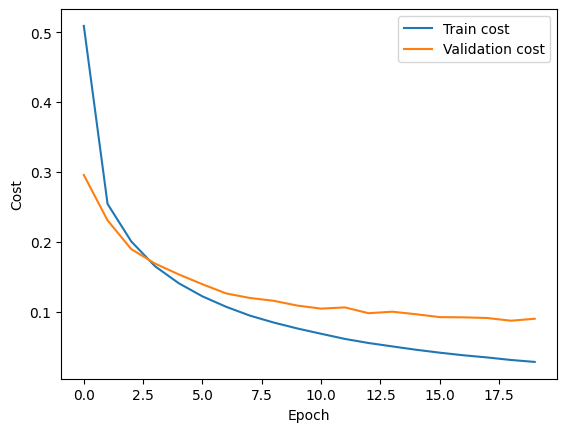

In [8]:
train_costs, val_costs = training.model_fit(model, X_train, y_train, 
                                       cost_function=loss.cross_entropy, epochs=epochs, 
                                       lr=learning_rate, X_val=X_val, y_val=y_val,
                                       batch_size=batch_size)

path = './trained_models/mnist_neuralnet'
model.save(path)

plt.plot(train_costs, label="Train cost")
plt.plot(val_costs, label="Validation cost")
plt.xlabel('Epoch')
plt.ylabel('Cost')
plt.legend()
plt.show()

#### Testen

In [9]:
# Model initialiseren en inladen

f_in, f_out = X_train.shape[1], y_train.shape[1]
neurons = [512, 256, f_out]

model = NeuralNetwork(act_func="softmax", f_in=f_in)
model.add(neurons)

path = './trained_models/mnist_neuralnet'
model.load(path)

print(model)

=========================Neural Network=========================
-- 1: Dense Layer (f_in: 784, f_out: 512), ReLU activation
-- 2: Dense Layer (f_in: 512, f_out: 256), ReLU activation
-- 3: Dense Layer (f_in: 256, f_out: 10), No activation
-- Activation function: softmax


In [10]:
pred = model.forward(X_test)
correct = y_test.argmax(axis=1) == pred.argmax(axis=1)

##### Accuracy

In [11]:
num_correct = correct.sum()
print(f"Test Accuracy: {(num_correct / X_test.shape[0]) * 100:.2f}%")

Test Accuracy: 97.62%


##### Fout geraden cijfers

Bar chart die laat zien hoe vaak cijfers fout geraden worden, waarbij opvalt dat het model met het cijfer 4 de meeste moeite heeft.

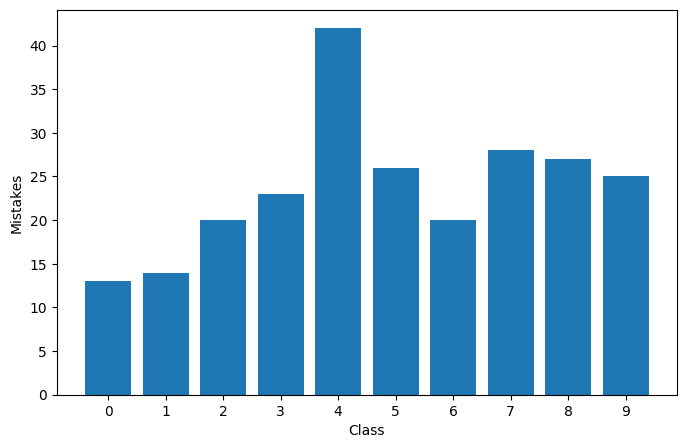

In [12]:
mistakes = y_test[~correct].argmax(axis=1)

classes, counts = np.unique(mistakes, return_counts=True)

plt.figure(figsize=(8,5))
plt.bar(classes, counts)
plt.xticks(classes)
plt.xlabel('Class')
plt.ylabel('Mistakes')
plt.show()

##### Confusion matrix

Hierin is te zien dat het model een 4 het vaakst misinterpreteert als een 9.

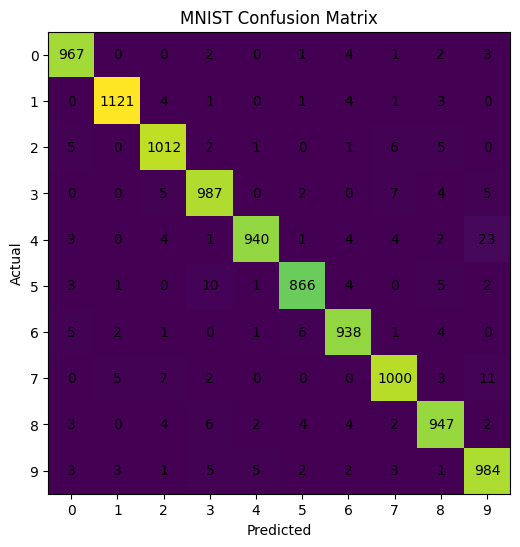

In [13]:
cm = np.zeros((10, 10), dtype=int)

for true, p in zip(y_test.argmax(axis=1), pred.argmax(axis=1)):
    cm[true, p] += 1

plt.figure(figsize=(6, 6))
plt.imshow(cm)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("MNIST Confusion Matrix")

plt.xticks(range(10))
plt.yticks(range(10))

for i in range(10):
    for j in range(10):
        plt.text(j, i, cm[i, j],
                 ha="center",
                 va="center")

plt.show()